## 1. Khai báo thư viện, cấu hình & kết nối GG Drive

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import base64
import gc
import hashlib
import json
import mimetypes
import random
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image, ImageOps

SEED = 42
IMAGE_SIZES = (96, 128, 160, 224)
ALPHA_THRESHOLD = 0.85
BATCH_SIZE = 8
EPOCHS = 30
MIN_IMAGES = 7
VAL_RATIO = 0.20
MIN_VAL_IMAGES = 2
STATES = ("fresh", "dried")
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
MOBILENET_WIDTH = 1.0

tf.keras.utils.set_random_seed(SEED)

PROJECT_DIR = Path("/content/drive/MyDrive/NCKH2026")
IMAGE_DIR = PROJECT_DIR / "DuocLieu"

assert PROJECT_DIR.is_dir(), f"Không tìm thấy: {PROJECT_DIR}"
assert IMAGE_DIR.is_dir(), f"Không tìm thấy: {IMAGE_DIR}"

RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
RUN_DIR = PROJECT_DIR / "experiments" / RUN_ID
DATASET_DIR = RUN_DIR / "dataset"
RUN_DIR.mkdir(parents=True, exist_ok=True)
DATASET_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Kích thước sẽ thử:", IMAGE_SIZES)
print("Ngưỡng alpha cố định:", ALPHA_THRESHOLD)
print("Kết quả sẽ lưu tại:", RUN_DIR)

Mounted at /content/drive
TensorFlow: 2.21.0
GPU: []
Kích thước sẽ thử: (96, 128, 160, 224)
Ngưỡng alpha cố định: 0.85
Kết quả sẽ lưu tại: /content/drive/MyDrive/NCKH2026/experiments/20261108_030535_284483


## 2. Quét và kiểm tra ảnh của cả hai trạng thái

In [ ]:
def list_images(folder):
    if not folder.is_dir():
        return []
    return sorted(
        path for path in folder.rglob("*")
        if path.is_file() and path.suffix.lower() in EXTENSIONS
    )


def is_valid_image(path):
    try:
        with Image.open(path) as image:
            image.verify()
        return True
    except Exception as error:
        print(f"Ảnh lỗi, sẽ bỏ qua: {path} ({error})")
        return False


species_dirs = sorted(
    path for path in IMAGE_DIR.iterdir()
    if path.is_dir() and (path / "raw").is_dir()
)

image_index = {state: {} for state in STATES}
summary_rows = []

for species_dir in species_dirs:
    row = {"loai": species_dir.name}

    for state in STATES:
        paths = [
            path
            for path in list_images(species_dir / "raw" / state)
            if is_valid_image(path)
        ]
        image_index[state][species_dir.name] = paths
        row[state] = len(paths)

    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).sort_values("loai").reset_index(drop=True)
summary_df.to_csv(DATASET_DIR / "dataset_summary.csv", index=False)
display(summary_df)

for state in STATES:
    eligible = summary_df.loc[
        summary_df[state] >= MIN_IMAGES, "loai"
    ].tolist()
    print(f"{state}: {len(eligible)} lớp đủ >= {MIN_IMAGES} ảnh")
    print(eligible)

,loai,fresh,dried
0,Vo_buoi,11,15
1,bo_cong_anh,7,11
2,cam_thao,3,39
3,cau_ky_tu,0,16
4,che_day,0,15
5,dinh_lang,107,6
6,do_trong_bac,0,39
7,don_do,0,12
8,gai_bo_ket,0,13
9,gung,13,0


fresh: 10 lớp đủ >= 7 ảnh
['Vo_buoi', 'bo_cong_anh', 'dinh_lang', 'gung', 'la_mo_long', 'la_xa_den', 'ma_de', 'rau_ma', 'sa', 'tia_to']
dried: 21 lớp đủ >= 7 ảnh
['Vo_buoi', 'bo_cong_anh', 'cam_thao', 'cau_ky_tu', 'che_day', 'do_trong_bac', 'don_do', 'gai_bo_ket', 'ha_thu_o_do', 'hoai_son', 'huyet_dang', 'long_nhan', 'ma_de', 'ngai_tuong', 'nu_tam_that_bac', 'qua_la_han', 'rau_ma', 'tao_do', 'tao_meo', 'thuc_dia', 'vo_quyt']


## 3. Chia train/validation độc lập cho fresh và dried

In [ ]:
def build_manifest(state):
    class_names = sorted(
        class_name
        for class_name, paths in image_index[state].items()
        if len(paths) >= MIN_IMAGES
    )

    assert len(class_names) >= 2, (
        f"Nhánh {state} cần ít nhất 2 lớp, "
        f"mỗi lớp có >= {MIN_IMAGES} ảnh hợp lệ."
    )

    records = []

    for label, class_name in enumerate(class_names):
        paths = image_index[state][class_name].copy()
        class_seed = SEED + sum(ord(char) for char in f"{state}:{class_name}")
        random.Random(class_seed).shuffle(paths)

        n_val = max(MIN_VAL_IMAGES, round(len(paths) * VAL_RATIO))
        n_val = min(n_val, len(paths) - 1)

        for index, path in enumerate(paths):
            records.append({
                "path": str(path),
                "class_name": class_name,
                "label": label,
                "state": state,
                "split": "val" if index < n_val else "train",
                "label_source": "human",
                "source_weight": 1.0,
            })

    manifest = pd.DataFrame(records)
    state_dir = DATASET_DIR / state
    state_dir.mkdir(parents=True, exist_ok=True)
    manifest.to_csv(state_dir / "split_manifest.csv", index=False)
    (state_dir / "class_names.json").write_text(
        json.dumps(class_names, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    return manifest, class_names


manifests = {}
class_names_by_state = {}

for state in STATES:
    manifest, class_names = build_manifest(state)
    manifests[state] = manifest
    class_names_by_state[state] = class_names

    print(f"\n=== {state.upper()} ===")
    display(pd.crosstab(manifest["class_name"], manifest["split"]))
    print("Các lớp:", class_names)



=== FRESH ===


split,train,val
class_name,,
Vo_buoi,9,2
bo_cong_anh,5,2
dinh_lang,86,21
gung,10,3
la_mo_long,18,5
la_xa_den,21,5
ma_de,11,3
rau_ma,22,6
sa,5,2


Các lớp: ['Vo_buoi', 'bo_cong_anh', 'dinh_lang', 'gung', 'la_mo_long', 'la_xa_den', 'ma_de', 'rau_ma', 'sa', 'tia_to']

=== DRIED ===


split,train,val
class_name,,
Vo_buoi,12,3
bo_cong_anh,9,2
cam_thao,31,8
cau_ky_tu,13,3
che_day,12,3
do_trong_bac,31,8
don_do,10,2
gai_bo_ket,10,3
ha_thu_o_do,13,3


Các lớp: ['Vo_buoi', 'bo_cong_anh', 'cam_thao', 'cau_ky_tu', 'che_day', 'do_trong_bac', 'don_do', 'gai_bo_ket', 'ha_thu_o_do', 'hoai_son', 'huyet_dang', 'long_nhan', 'ma_de', 'ngai_tuong', 'nu_tam_that_bac', 'qua_la_han', 'rau_ma', 'tao_do', 'tao_meo', 'thuc_dia', 'vo_quyt']


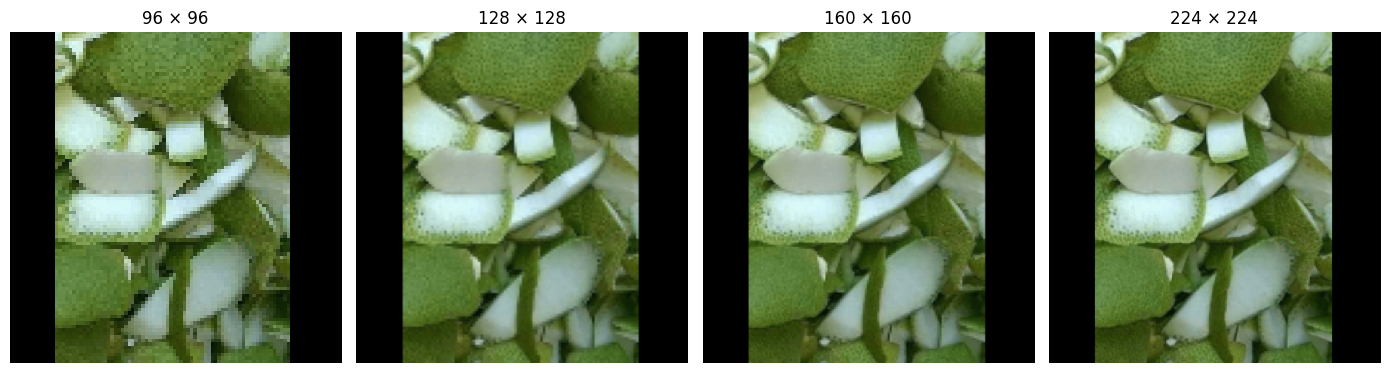

In [ ]:
def decode_and_resize(path, image_size):
    content = tf.io.read_file(path)
    image = tf.io.decode_image(
        content,
        channels=3,
        expand_animations=False,
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize_with_pad(image, image_size, image_size)
    return tf.cast(image, tf.float32)


def make_dataset(manifest, split, image_size, training=False):
    rows = manifest.loc[manifest["split"] == split]
    paths = rows["path"].tolist()
    labels = rows["label"].to_numpy(dtype="int32")
    assert paths, f"Tập {split} không có ảnh"

    def mapper(path, label):
        return decode_and_resize(path, image_size), label

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(mapper, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.cache()

    if training:
        dataset = dataset.shuffle(
            len(paths),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


preview_state = "fresh"
preview_path = manifests[preview_state].iloc[0]["path"]

fig, axes = plt.subplots(1, len(IMAGE_SIZES), figsize=(14, 4))
for axis, image_size in zip(axes, IMAGE_SIZES):
    image = decode_and_resize(tf.constant(preview_path), image_size)
    axis.imshow(np.clip(image.numpy(), 0, 255).astype("uint8"))
    axis.set_title(f"{image_size} × {image_size}")
    axis.axis("off")
plt.tight_layout()
plt.show()

## 4. Tạo pipeline và xem thử ảnh input

In [ ]:
def read_image(path, label, image_size):
    content = tf.io.read_file(path)

    image = tf.io.decode_image(
        content,
        channels=3,
        expand_animations=False,
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize_with_pad(
        image,
        image_size,
        image_size,
    )

    image = tf.cast(image, tf.float32)

    return image, label


def make_dataset(
    manifest,
    split,
    image_size,
    training=False,
):
    rows = manifest.loc[
        manifest["split"] == split
    ]

    paths = rows["path"].tolist()

    labels = rows["label"].to_numpy(
        dtype="int32"
    )

    assert paths, f"Tập {split} không có ảnh"

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    # Wrapper để truyền thêm image_size vào read_image
    def map_image(path, label):
        return read_image(
            path,
            label,
            image_size,
        )

    dataset = dataset.map(
        map_image,
        num_parallel_calls=tf.data.AUTOTUNE,
    )

    dataset = dataset.cache()

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    return dataset.batch(
        BATCH_SIZE
    ).prefetch(
        tf.data.AUTOTUNE
    )

## 5. Tạo MobileNetV2 cho từng nhánh

In [ ]:
def build_model(num_classes, state, image_size):
    layers = tf.keras.layers

    augmentation = tf.keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.10),
        layers.RandomContrast(0.10),
    ], name=f"{state}_augmentation")

    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(image_size, image_size, 3),
        alpha=MOBILENET_WIDTH,
        include_top=False,
        weights="imagenet",
    )
    base_model.trainable = False

    inputs = tf.keras.Input(
        shape=(image_size, image_size, 3),
        name="image",
    )
    x = augmentation(inputs)
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.25)(x)
    outputs = layers.Dense(
        num_classes,
        activation="softmax",
        name="classifier",
    )(x)

    model = tf.keras.Model(
        inputs,
        outputs,
        name=f"duoclieu_{state}_{image_size}_mobilenetv2",
    )
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=[
            tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
            tf.keras.metrics.SparseTopKCategoricalAccuracy(
                k=min(2, num_classes),
                name="top2_accuracy",
            ),
        ],
    )
    return model

## 6. Train 2 model theo 2 hướng

In [ ]:
def calculate_class_weights(manifest):
    train_rows = manifest.loc[manifest["split"] == "train"]
    counts = train_rows["label"].value_counts().sort_index()
    total = len(train_rows)
    num_classes = len(counts)
    return {
        int(label): total / (num_classes * count)
        for label, count in counts.items()
    }


def experiment_dir(image_size, state):
    return RUN_DIR / f"img_{image_size}" / state


def train_experiment(image_size, state, epochs=EPOCHS):
    tf.keras.backend.clear_session()
    gc.collect()

    output_dir = experiment_dir(image_size, state)
    output_dir.mkdir(parents=True, exist_ok=True)

    manifest = manifests[state]
    class_names = class_names_by_state[state]
    train_ds = make_dataset(manifest, "train", image_size, training=True)
    val_ds = make_dataset(manifest, "val", image_size, training=False)
    class_weights = calculate_class_weights(manifest)

    model = build_model(len(class_names), state, image_size)
    best_model_path = output_dir / "best_model.keras"

    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            str(best_model_path),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            verbose=1,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=6,
            restore_best_weights=True,
            verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            mode="min",
            factor=0.5,
            patience=2,
            min_lr=1e-6,
            verbose=1,
        ),
        tf.keras.callbacks.CSVLogger(str(output_dir / "history.csv")),
    ]

    print(f"\n===== TRAIN {state.upper()} | {image_size}×{image_size} =====")
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        callbacks=callbacks,
        class_weight=class_weights,
        verbose=1,
    )

    best_model = tf.keras.models.load_model(str(best_model_path))
    metrics = best_model.evaluate(val_ds, return_dict=True, verbose=0)
    history_df = pd.DataFrame(history.history)
    history_df.to_csv(output_dir / "history_from_memory.csv", index=False)

    result = {
        "image_size": image_size,
        "state": state,
        **metrics,
        "model_size_mb": best_model_path.stat().st_size / (1024 ** 2),
    }

    del model, best_model, train_ds, val_ds
    tf.keras.backend.clear_session()
    gc.collect()
    return history_df, result


histories = {}
training_results = []

for image_size in IMAGE_SIZES:
    for state in STATES:
        history_df, result = train_experiment(image_size, state)
        histories[(image_size, state)] = history_df
        training_results.append(result)

training_summary = pd.DataFrame(training_results)
training_summary.to_csv(RUN_DIR / "training_summary.csv", index=False)
display(training_summary)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

===== TRAIN FRESH | 96×96 =====
Epoch 1/30
26/27 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.4035 - loss: 2.9186 - top2_accuracy: 0.5063
Epoch 1: val_loss improved from None to 1.28391, saving model to /content/drive/MyDrive/NCKH2026/experiments/20261108_030535_284483/img_96/fresh/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/NCKH2026/experiments/20261108_030535_284483/img_96/fresh/best_model.keras
27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 226ms/step - accuracy: 0.4689 - loss: 3.0527 - top2_accuracy: 0.5598 - val_accuracy: 0.5370 - val_loss: 1.2839 - val_top2_accuracy: 0.7778 - learning_rate: 0.0010
Epoch 2/30
26/27 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.5225 - loss: 1.8565 - top2_accuracy: 0.7152
Epoch 2: val_loss improved from 1.28391 to 0.89533, saving model to /content/drive/MyDrive/NCKH2026/experiments/20261108_030535_284483/img_96/fresh/best_model.keras

Epoch 2: finished saving model to /content/dri

## 7. Vẽ learning line cho 2 model

In [ ]:
fig, axes = plt.subplots(len(STATES), 2, figsize=(14, 10))

for row_index, state in enumerate(STATES):
    for image_size in IMAGE_SIZES:
        history_df = histories[(image_size, state)]
        axes[row_index, 0].plot(
            history_df["val_loss"],
            label=f"{image_size}",
        )
        axes[row_index, 1].plot(
            history_df["val_accuracy"],
            label=f"{image_size}",
        )

    axes[row_index, 0].set_title(f"{state} - validation loss")
    axes[row_index, 1].set_title(f"{state} - validation accuracy")
    axes[row_index, 0].set_xlabel("Epoch")
    axes[row_index, 1].set_xlabel("Epoch")
    axes[row_index, 1].set_ylim(0, 1.05)
    axes[row_index, 0].grid(alpha=0.3)
    axes[row_index, 1].grid(alpha=0.3)
    axes[row_index, 0].legend(title="Kích thước")
    axes[row_index, 1].legend(title="Kích thước")

plt.tight_layout()
plt.savefig(RUN_DIR / "size_learning_curves.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Đánh giá tại ngưỡng 0.95

In [ ]:
from sklearn.metrics import f1_score


def validation_predictions(model_path, state, image_size):
    manifest = manifests[state]
    class_names = class_names_by_state[state]
    model = tf.keras.models.load_model(str(model_path))
    val_ds = make_dataset(manifest, "val", image_size, training=False)
    probabilities = model.predict(val_ds, verbose=0)

    rows = (
        manifest.loc[manifest["split"] == "val"]
        .copy()
        .reset_index(drop=True)
    )
    predictions = rows[[
        "path", "class_name", "label", "state"
    ]].rename(columns={
        "class_name": "true_class",
        "label": "true_label",
    })
    predictions["pred_label"] = np.argmax(probabilities, axis=1)
    predictions["pred_class"] = [
        class_names[index] for index in predictions["pred_label"]
    ]
    predictions["confidence"] = np.max(probabilities, axis=1)
    predictions["correct"] = (
        predictions["true_label"] == predictions["pred_label"]
    )

    del model, val_ds
    tf.keras.backend.clear_session()
    gc.collect()
    return predictions


def fixed_alpha_metrics(predictions, alpha=ALPHA_THRESHOLD):
    accepted = predictions["confidence"] >= alpha
    accepted_count = int(accepted.sum())
    total = len(predictions)

    return {
        "alpha": alpha,
        "validation_images": total,
        "accuracy_all": float(predictions["correct"].mean()),
        "macro_f1": float(f1_score(
            predictions["true_label"],
            predictions["pred_label"],
            average="macro",
            zero_division=0,
        )),
        "local_coverage": accepted_count / total,
        "cloud_rate": 1 - accepted_count / total,
        "selective_accuracy": (
            float(predictions.loc[accepted, "correct"].mean())
            if accepted_count else np.nan
        ),
        "wrong_accept_rate": float(
            (accepted & ~predictions["correct"]).mean()
        ),
    }


predictions_by_experiment = {}
comparison_rows = []

for image_size in IMAGE_SIZES:
    for state in STATES:
        output_dir = experiment_dir(image_size, state)
        model_path = output_dir / "best_model.keras"
        predictions = validation_predictions(model_path, state, image_size)
        predictions.to_csv(output_dir / "val_predictions.csv", index=False)
        predictions_by_experiment[(image_size, state)] = predictions

        comparison_rows.append({
            "image_size": image_size,
            "state": state,
            "model_size_mb": model_path.stat().st_size / (1024 ** 2),
            **fixed_alpha_metrics(predictions),
        })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(RUN_DIR / "size_comparison_alpha_095.csv", index=False)
display(comparison_df.sort_values(["state", "image_size"]))

## 9. Biểu đồ chọn kích thước

In [ ]:
fig, axes = plt.subplots(1, len(STATES), figsize=(14, 5), squeeze=False)

for column, state in enumerate(STATES):
    data = comparison_df[comparison_df["state"] == state].sort_values("image_size")
    axis = axes[0, column]
    axis.plot(
        data["image_size"],
        data["accuracy_all"],
        marker="o",
        label="Accuracy toàn bộ",
    )
    axis.plot(
        data["image_size"],
        data["local_coverage"],
        marker="o",
        label="Xử lý cục bộ tại α=0.95",
    )
    axis.plot(
        data["image_size"],
        data["wrong_accept_rate"],
        marker="o",
        label="Chấp nhận sai",
    )
    axis.set_title(state)
    axis.set_xlabel("Kích thước ảnh")
    axis.set_ylim(0, 1.05)
    axis.set_xticks(IMAGE_SIZES)
    axis.grid(alpha=0.3)
    axis.legend()

plt.tight_layout()
plt.savefig(RUN_DIR / "size_comparison_alpha_095.png", dpi=160)
plt.show()

## 10. Chọn model Student để vận hành

In [ ]:
SELECTED_IMAGE_SIZE = 128

assert SELECTED_IMAGE_SIZE in IMAGE_SIZES

STUDENT_MODEL_PATHS = {
    state: experiment_dir(SELECTED_IMAGE_SIZE, state) / "best_model.keras"
    for state in STATES
}

MODEL_CACHE = {}


def load_student_model(state):
    if state not in STATES:
        raise ValueError(f"state phải thuộc {STATES}")

    model_path = STUDENT_MODEL_PATHS[state]
    cache_key = (state, str(model_path))
    if cache_key not in MODEL_CACHE:
        MODEL_CACHE[cache_key] = tf.keras.models.load_model(str(model_path))
    return MODEL_CACHE[cache_key]


def student_predict(image_path, state):
    model = load_student_model(state)
    class_names = class_names_by_state[state]
    image = decode_and_resize(
        tf.constant(str(image_path)),
        SELECTED_IMAGE_SIZE,
    )
    probabilities = model(
        tf.expand_dims(image, axis=0),
        training=False,
    ).numpy()[0]

    predicted_label = int(np.argmax(probabilities))
    confidence = float(probabilities[predicted_label])
    return {
        "state": state,
        "predicted_class": class_names[predicted_label],
        "confidence": confidence,
        "alpha": ALPHA_THRESHOLD,
        "decision": (
            "accept_local"
            if confidence >= ALPHA_THRESHOLD
            else "send_to_gemini"
        ),
    }

In [ ]:
%pip install -q -U kaggle